# НИР: обнаружение транспорта и пешеходов на снимках с БЛА (VisDrone, YOLO26) — версия для Kaggle

**Настройки ноутбука (справа, Session options):** Accelerator = **GPU T4 x2** (не P100), Internet = **On** (нужен для pip, весов `yolo26s.pt` и скачивания VisDrone), Persistence = **Files only** (файлы из `/kaggle/working` сохраняются между сессиями).

**Порядок работы:** 0 → 1 → 2 → 2а → (2б своя архитектура) → (3 замер, один раз) → 4 обучение → 5 кривые → 6 валидация → 7 AP по размерам → 8 тест (один раз, в самом конце).

Параметры эксперимента меняются **только** в ячейке «Конфигурация». Результаты пишутся в `/kaggle/working/runs`.
Для длинного обучения удобнее **Save Version → Save & Run All**: ноутбук выполняется в фоне (сессия до 12 ч), вкладку держать открытой не нужно. Тогда в конфигурации должен быть выбран ровно один запуск; запускаются все ячейки подряд.
После обрыва: заново запустить ячейки 0-2б и ячейку обучения, она продолжит с `last.pt` (если он есть в `/kaggle/working/runs` или в подключённом Input, см. ячейку обучения).

## 0. Окружение, Drive, пакеты

In [1]:
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
!pip install -q ultralytics==8.4.183 pycocotools   # версия зафиксирована для воспроизводимости
import torch, ultralytics
ultralytics.checks()
N_GPU = torch.cuda.device_count()
print("Видимых GPU:", N_GPU)
assert N_GPU >= 1, "GPU не включён: Session options -> Accelerator -> GPU T4 x2"

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7089.6/8156.9 GB disk)
Видимых GPU: 2


## 1. Конфигурация эксперимента

In [2]:
from pathlib import Path

#MODEL      = "yolo26s.pt"    # базовая модель с весами COCO; для сравнения: yolo26n.pt
# Собственная архитектура (после раздела 2б):
MODEL      = str(Path("/kaggle/working/configs/yolo26s-visdrone-p2.yaml"))      # штатный P2 (P2-P5)
# MODEL      = str(Path("/kaggle/working/configs/yolo26s-visdrone-p2-p4.yaml"))   # свой вариант (P2-P4)
PRETRAINED = "yolo26s.pt" #перенести веса; None = с нуля
PRETRAINED_MAX_LAYER = 16    # переносить веса только из слоёв 0..N (остальные индексы в P2-конфигах сдвинуты)
IMGSZ     = 640              # 640 / 960
BATCH     = 16               # ОБЩИЙ батч. При двух GPU делится пополам (16 -> 8 на карту); на одной T4: P2 -> 8, база 640 -> 16, 960 -> 8
EPOCHS    = 50
SEED      = 0
OPTIMIZER = "SGD"            # фиксируем для честного сравнения; "auto" = штатный рецепт
LR0       = 0.01
USE_DDP   = True             # True = обучение на двух T4; False = на одной (как в Colab)
WORKERS   = 4                # Ultralytics сам делит число потоков между GPU
CACHE     = "ram" if IMGSZ <= 640 else False   # декодирование больших JPEG на 4 ядрах - узкое место; на 960 кэш в ОЗУ не влезает при двух процессах

USE_DDP = USE_DDP and N_GPU >= 2
DEVICE  = [0, 1] if USE_DDP else 0

WORK = Path("/kaggle/working")
TEMP = Path("/kaggle/temp") if Path("/kaggle/temp").exists() else Path("/tmp")   # не попадает в Output
RUNS = WORK / "runs"; RUNS.mkdir(parents=True, exist_ok=True)

is_cfg = MODEL.endswith(".yaml")
TAG   = ("_tl" if PRETRAINED else "_scratch") if is_cfg else ""
NAME  = f"{Path(MODEL).stem}{TAG}_{IMGSZ}"
print("Запуск:", NAME, "->", RUNS / NAME)
print("Устройство:", DEVICE, "| общий батч:", BATCH, "| cache:", CACHE)

Запуск: yolo26s-visdrone-p2_tl_640 -> /kaggle/working/runs/yolo26s-visdrone-p2_tl_640
Устройство: [0, 1] | общий батч: 16 | cache: ram


In [3]:
import json, os, shutil, subprocess, threading, urllib.request, zipfile
from pathlib import Path
from kaggle_secrets import UserSecretsClient

GDRIVE_DIR = "uav_nir"      # та же папка, что в Colab: Мой диск/uav_nir
SYNC_EVERY = 600            # как часто выгружать на Drive во время обучения, сек

# 1. rclone
RCLONE = "/tmp/rclone_bin/rclone"
URLS = [
    "https://downloads.rclone.org/rclone-current-linux-amd64.zip",
    "https://downloads.rclone.org/v1.68.2/rclone-v1.68.2-linux-amd64.zip",
    "https://github.com/rclone/rclone/releases/download/v1.68.2/rclone-v1.68.2-linux-amd64.zip",
]
if not Path(RCLONE).exists():
    z = Path("/tmp/rclone.zip")
    for url in URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=60) as r, open(z, "wb") as f:
                shutil.copyfileobj(r, f)
            break
        except Exception as e:
            print("не удалось", url, "->", repr(e))
    else:
        raise RuntimeError("rclone скачать не удалось, см. сообщения выше")
    zipfile.ZipFile(z).extractall("/tmp/rclone_x")
    Path(RCLONE).parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(next(Path("/tmp/rclone_x").glob("*/rclone")), RCLONE)
    os.chmod(RCLONE, 0o755)
print(rc_ver := subprocess.run([RCLONE, "version"], capture_output=True, text=True).stdout.splitlines()[0])

# 2. конфиг с токеном из секретов (в /kaggle/working не пишется, в Output не попадёт)
token = json.dumps(json.loads(UserSecretsClient().get_secret("RCLONE_TOKEN")))
conf = Path.home() / ".config" / "rclone" / "rclone.conf"
conf.parent.mkdir(parents=True, exist_ok=True)
conf.write_text(f"[gdrive]\ntype = drive\nscope = drive\ntoken = {token}\n")
os.chmod(conf, 0o600)

def rc(*args, check=True):
    r = subprocess.run([RCLONE, *args], capture_output=True, text=True)
    if check and r.returncode:
        raise RuntimeError(f"rclone {args[0]}: {r.stderr[-400:]}")
    return r

def drive_pull(name):
    # Скачать прошлый запуск (для продолжения после обрыва)
    src = f"gdrive:{GDRIVE_DIR}/runs/{name}"
    if rc("lsf", src, check=False).returncode:
        print("На Drive нет", src); return False
    rc("copy", src, str(RUNS / name))
    print("Скачано с Drive:", src); return True

def drive_push(name=None):
    # Выгрузить запуск (или все runs) и конфиги; predictions.json большие, их пропускаем
    ex = ["--exclude", "predictions.json"]
    if name:
        rc("copy", str(RUNS / name), f"gdrive:{GDRIVE_DIR}/runs/{name}", *ex)
    else:
        rc("copy", str(RUNS), f"gdrive:{GDRIVE_DIR}/runs", *ex)
    if (WORK / "configs").exists():
        rc("copy", str(WORK / "configs"), f"gdrive:{GDRIVE_DIR}/configs")

_stop = threading.Event()
def _sync_loop():
    while not _stop.wait(SYNC_EVERY):
        try: drive_push(NAME)
        except Exception as e: print("sync на Drive не удался:", e)
def start_sync():
    _stop.clear(); threading.Thread(target=_sync_loop, daemon=True).start()
def stop_sync():
    _stop.set()
    try: drive_push(NAME)
    except Exception as e: print("финальная выгрузка не удалась:", e)

# проверка
rc("mkdir", f"gdrive:{GDRIVE_DIR}")
print("Содержимое Drive/", GDRIVE_DIR, ":", rc("lsf", f"gdrive:{GDRIVE_DIR}").stdout.split())

rclone v1.75.2
Содержимое Drive/ uav_nir : ['configs/', 'runs/']


## 2. Датасет VisDrone (на локальный диск) и yaml

In [4]:
import ultralytics.data.utils as du
from ultralytics import settings

DATASETS = TEMP / "datasets"; DATASETS.mkdir(parents=True, exist_ok=True)
try:
    settings.update({"datasets_dir": str(DATASETS), "wandb": False})
except Exception as e:
    print("settings.update:", e)
du.DATASETS_DIR = DATASETS            # константа читается при импорте, поэтому подменяем и её

ROOT = DATASETS / "VisDrone"
if not (ROOT / "images" / "train").exists():
    du.check_det_dataset("VisDrone.yaml")         # скачает и сконвертирует в формат YOLO (нужен Internet: On)
if not (ROOT / "images" / "train").exists():
    raise RuntimeError(f"VisDrone не найден в {ROOT}. Содержимое {DATASETS}: {[p.name for p in DATASETS.glob('*')]}")

DATA_YAML = str(WORK / "visdrone.yaml")
NAMES = ["pedestrian", "people", "bicycle", "car", "van",
         "truck", "tricycle", "awning-tricycle", "bus", "motor"]
Path(DATA_YAML).write_text(
    f"path: {ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {n}\n" for i, n in enumerate(NAMES)))

for s in ["train", "val", "test"]:
    print(f"{s:6s} изображений={len(list((ROOT/'images'/s).glob('*.jpg')))}  "
          f"меток={len(list((ROOT/'labels'/s).glob('*.txt')))}")


WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/tmp/datasets/VisDrone/images/val'
Unzipping /tmp/datasets/VisDrone/VisDrone2019-DET-val.zip to /tmp/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 732.3files/s 1.5s
Unzipping /tmp/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /tmp/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 742.1files/s 4.3s
Unzipping /tmp/datasets/VisDrone/VisDrone2019-DET-train.zip to /tmp/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 1.0Kfiles/s 12.9s
Converting train: ━━━━━━━━━━━━ 6471 2.0Kit/s 3.8s
Converting val: ━━━━━━━━━━━━ 548 1.3Kit/s 0.3s
Converting test: ━━━━━━━━━━━━ 1610 2.1Kit/s 0.7s
Dataset download success ✅ (34.4s), saved to /tmp/datasets

train  изображений=6471  меток=6471
val    изображений=548  меток=548
test   изображений=1610  меток=1610


## 2а. Вспомогательные функции: перенос весов в собственную архитектуру
Переносятся только слои 0..N; остальное остаётся со случайной инициализацией (в P2-конфигах индексы слоёв сдвинуты, и совпадения по форме за пределами N случайны).

**Почему две ветки.** На одной GPU работает проверенный в Colab путь `transfer_weights` (`.load()` на объекте модели). При обучении на двух GPU (DDP) Ultralytics запускает процессы заново по имени модели, и веса, перенесённые в объект, терялись бы. Поэтому для DDP перенесённые веса сохраняются в файл `*_init.pt`, и обучение стартует из него. После записи файл проверяется; в логе обучения должна быть строка `Transferred 886/902 items` (так же, как в Colab).

In [5]:
import torch
from copy import deepcopy
from ultralytics import YOLO

def transfer_weights(cfg, weights, max_layer):
    # Модель из YAML; из weights переносятся только слои 0..max_layer, остальное остаётся случайным
    torch.manual_seed(SEED)
    fresh = YOLO(cfg).model.state_dict()                 # свежая случайная инициализация
    m = YOLO(cfg).load(weights)                          # частичный перенос; задаёт ckpt, нужный для train()
    sd = m.model.state_dict()
    for k in sd:
        if int(k.split(".")[1]) > max_layer:
            sd[k] = fresh[k].clone()
    m.model.load_state_dict(sd)
    src = YOLO(weights).model.state_dict()
    keys = [k for k in sd if int(k.split(".")[1]) <= max_layer and k in src and src[k].shape == sd[k].shape]
    same = all(torch.equal(sd[k].cpu(), src[k].cpu()) for k in keys)
    print(f"Из слоёв 0-{max_layer} перенесено тензоров: {len(keys)}; совпадают с {weights}: {same}")
    return m

def make_init_ckpt(cfg, weights, max_layer, out):
    # Для DDP: сохраняем модель с перенесёнными весами как обычный .pt (Model.save сохранил бы исходную модель, поэтому torch.save)
    m = transfer_weights(cfg, weights, max_layer)
    out = Path(out); out.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"model": deepcopy(m.model).float().cpu(), "ema": None, "optimizer": None, "updates": None,
                "epoch": -1, "best_fitness": None, "train_args": {}, "version": ultralytics.__version__}, out)
    back = YOLO(str(out)).model.state_dict()             # проверка: файл читается, веса слоёв 0..N на месте
    src = YOLO(weights).model.state_dict()
    keys = [k for k in back if int(k.split(".")[1]) <= max_layer and k in src and src[k].shape == back[k].shape]
    ok = all(torch.equal(back[k].cpu(), src[k].cpu()) for k in keys)
    print(f"{out.name}: тензоров слоёв 0-{max_layer} в файле {len(keys)}, совпадают с {weights}: {ok}")
    assert ok and len(keys) > 0, "Файл начальных весов некорректен"
    return YOLO(str(out))

def prepare_model(model, pretrained):
    if not pretrained:
        return YOLO(model)
    if USE_DDP:
        return make_init_ckpt(model, pretrained, PRETRAINED_MAX_LAYER, TEMP / "init" / f"{Path(model).stem}_init.pt")
    return transfer_weights(model, pretrained, PRETRAINED_MAX_LAYER)

## 2б. Собственная архитектура: YOLO26s с головой P2
Пропусти раздел, если обучаешь стандартную модель. Здесь строятся два конфига: штатный P2 (уровни P2-P5) и собственный P2-P4 (убран самый глубокий уровень P5). Затем проверяются размер моделей и перенос весов. Для обучения в конфигурации задай `MODEL` и `PRETRAINED`.

In [6]:
import ultralytics, shutil
CFG_DIR = Path(ultralytics.__file__).parent / "cfg" / "models"
found = sorted(CFG_DIR.rglob("yolo26*.yaml"))
SRC = next((p for p in found if p.name == "yolo26-p2.yaml"), None)
assert SRC is not None, "yolo26-p2.yaml не найден"

# В имени файла должно быть «yolo26s»: по нему выбирается масштаб модели
CONFIGS = WORK / "configs"; CONFIGS.mkdir(exist_ok=True)      # /kaggle/working сохраняется как Output
CUSTOM_CFG = CONFIGS / "yolo26s-visdrone-p2.yaml"
shutil.copy(SRC, CUSTOM_CFG)

# Вариант P2-P4: удаляем Conv + Concat + C3k2 уровня P5 и убираем его вход из Detect
txt = CUSTOM_CFG.read_text().splitlines()
i = next(k for k, l in enumerate(txt) if "cat head P5" in l)
del txt[i - 1:i + 2]
txt = [l.replace("[[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)",
                 "[[19, 22, 25], 1, Detect, [nc]] # Detect(P2, P3, P4)") for l in txt]
CFG_P2P4 = CONFIGS / "yolo26s-visdrone-p2-p4.yaml"
CFG_P2P4.write_text(chr(10).join(txt) + chr(10))
assert "[[19, 22, 25], 1, Detect, [nc]]" in CFG_P2P4.read_text()
print(chr(10).join(txt[-14:]))

  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]] # cat backbone P2
  - [-1, 2, C3k2, [128, True]] # 19 (P2/4-xsmall)

  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]] # cat head P3
  - [-1, 2, C3k2, [256, True]] # 22 (P3/8-small)

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]] # cat head P4
  - [-1, 2, C3k2, [512, True]] # 25 (P4/16-medium)


  - [[19, 22, 25], 1, Detect, [nc]] # Detect(P2, P3, P4)


In [7]:
from ultralytics import YOLO
print("=== базовая YOLO26s ===");  YOLO("yolo26s.yaml").info()
for cfg in (CUSTOM_CFG, CFG_P2P4):
    print("===", cfg.name, "==="); YOLO(str(cfg)).info()

=== базовая YOLO26s ===
YOLO26s summary: 260 layers, 10,009,784 parameters, 10,009,784 gradients, 23.1 GFLOPs
=== yolo26s-visdrone-p2.yaml ===
YOLO26s-visdrone-p2 summary: 329 layers, 9,765,856 parameters, 9,765,856 gradients, 28.0 GFLOPs
=== yolo26s-visdrone-p2-p4.yaml ===
YOLO26s-visdrone-p2-p4 summary: 276 layers, 7,058,136 parameters, 7,058,136 gradients, 25.7 GFLOPs


In [8]:
# Какие слои совпадут по имени и форме тензоров с yolo26s.pt (так работает .load)
src = YOLO("yolo26s.pt").model.state_dict()
for cfg in (CUSTOM_CFG, CFG_P2P4):
    dst = YOLO(str(cfg)).model.state_dict()
    layers = {}
    for k, v in dst.items():
        i = int(k.split(".")[1]); a = layers.setdefault(i, [0, 0]); a[1] += 1
        a[0] += int(k in src and src[k].shape == v.shape)
    print(cfg.name)
    print("  полностью  :", sorted(i for i, (a, b) in layers.items() if a == b))
    print("  частично   :", sorted(i for i, (a, b) in layers.items() if 0 < a < b))
    print("  не переносятся:", sorted(i for i, (a, b) in layers.items() if a == 0))

yolo26s-visdrone-p2.yaml
  полностью  : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13, 16]
  частично   : [19, 20, 22]
  не переносятся: [23, 25, 26, 28, 29]
yolo26s-visdrone-p2-p4.yaml
  полностью  : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13, 16]
  частично   : [19, 20, 22]
  не переносятся: [23, 25, 26]


## 3. Замер времени эпохи (один раз на модель и разрешение)
1 эпоха на 20 % train, мозаика включена. Полная эпоха ≈ время обучения × 5 + время валидации. Результаты временные, в `/kaggle/temp/tmp_runs`.

In [9]:
from ultralytics import YOLO

def time_run(model, imgsz, bs, pretrained=None):
    m = prepare_model(model, pretrained)
    m.train(data=DATA_YAML, imgsz=imgsz, epochs=1, fraction=0.2, batch=bs, device=DEVICE,
            workers=WORKERS, cache=CACHE, seed=SEED, close_mosaic=0, optimizer=OPTIMIZER, lr0=LR0,
            plots=False, project=str(TEMP / "tmp_runs"), name=f"t_{Path(model).stem}_{imgsz}", exist_ok=True)

# bs - общий батч (при двух GPU делится пополам)
# time_run("yolo26s.pt", 640, 16)                                                 # базовая
time_run(str(CUSTOM_CFG), 640, 16, pretrained="yolo26s.pt")                     # P2 (при USE_DDP=False поставь 8)
# time_run(str(CFG_P2P4), 640, 16, pretrained="yolo26s.pt")

Transferred 360/902 items from pretrained weights
Из слоёв 0-16 перенесено тензоров: 348; совпадают с yolo26s.pt: True
yolo26s-visdrone-p2_init.pt: тензоров слоёв 0-16 в файле 348, совпадают с yolo26s.pt: True
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/visdrone.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.2, f

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



1 epochs completed in 0.019 hours.
Optimizer stripped from /tmp/tmp_runs/t_yolo26s-visdrone-p2_640/weights/last.pt, 20.0MB
Optimizer stripped from /tmp/tmp_runs/t_yolo26s-visdrone-p2_640/weights/best.pt, 20.0MB

Validating /tmp/tmp_runs/t_yolo26s-visdrone-p2_640/weights/best.pt...
YOLO26s-visdrone-p2 summary (fused): 151 layers, 9,434,120 parameters, 0 gradients, 24.6 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.9it/s 6.3s
                   all        548      38759      0.024     0.0128    0.00191   0.000351
            pedestrian        520       8844    0.00192     0.0308    0.00226   0.000398
                people        482       5125     0.0186    0.00293   0.000417   4.87e-05
               bicycle        364       1287          0          0          0          0
                   car        515      14064      0.192     0.0741     0.0153    0.00283
                   van        421       1975    7

## 4. Обучение (с автоматическим продолжением)

In [10]:
import shutil
import pandas as pd
from ultralytics import YOLO

run_dir = RUNS / NAME
last, res_csv = run_dir / "weights" / "last.pt", run_dir / "results.csv"

if not last.exists():
    drive_pull(NAME)                      # сначала Drive
if not last.exists():                     # потом подключённые Input
    cands = [p for pat in (f"kaggle/input/*/runs/{NAME}", f"kaggle/input/*/*/runs/{NAME}")
             for p in Path("/").glob(pat) if (p / "weights" / "last.pt").exists()]
    if cands:
        shutil.copytree(cands[0], run_dir, dirs_exist_ok=True)
        print("Восстановлено из", cands[0])

done_epochs = len(pd.read_csv(res_csv)) if res_csv.exists() else 0

start_sync()
try:
    if done_epochs >= EPOCHS:
        print(f"Обучение уже завершено ({done_epochs} эпох), пропускаю.")
    elif last.exists():
        print(f"Продолжаю с эпохи {done_epochs + 1}")
        YOLO(str(last)).train(resume=True)
    else:
        m = prepare_model(MODEL, PRETRAINED)
        r = m.train(data=DATA_YAML, imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, device=DEVICE,
                    workers=WORKERS, cache=CACHE, optimizer=OPTIMIZER, lr0=LR0, seed=SEED,
                    close_mosaic=10, save_period=10, project=str(RUNS), name=NAME, exist_ok=True)
finally:
    stop_sync()

Скачано с Drive: gdrive:uav_nir/runs/yolo26s-visdrone-p2_tl_640
Продолжаю с эпохи 22
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/visdrone.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rati

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      23/50      7.49G      1.952      1.598   0.002205        227        640: 100% ━━━━━━━━━━━━ 405/405 3.0it/s 2:15
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.7it/s 4.9s
                   all        548      38759      0.491      0.378      0.375      0.213

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      24/50      9.26G       1.93      1.582   0.002244        372        640: 100% ━━━━━━━━━━━━ 405/405 3.0it/s 2:14
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.6it/s 5.0s
                   all        548      38759      0.497      0.376       0.38      0.216

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      25/50      8.34G      1.937       1.57   0.002212        288        640: 100% ━━━━━━━━━━━

## 5. Кривые обучения и лучшая эпоха

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
Лучшая эпоха: 46  mAP50=0.4063  mAP50-95=0.2344  P=0.5244  R=0.3993


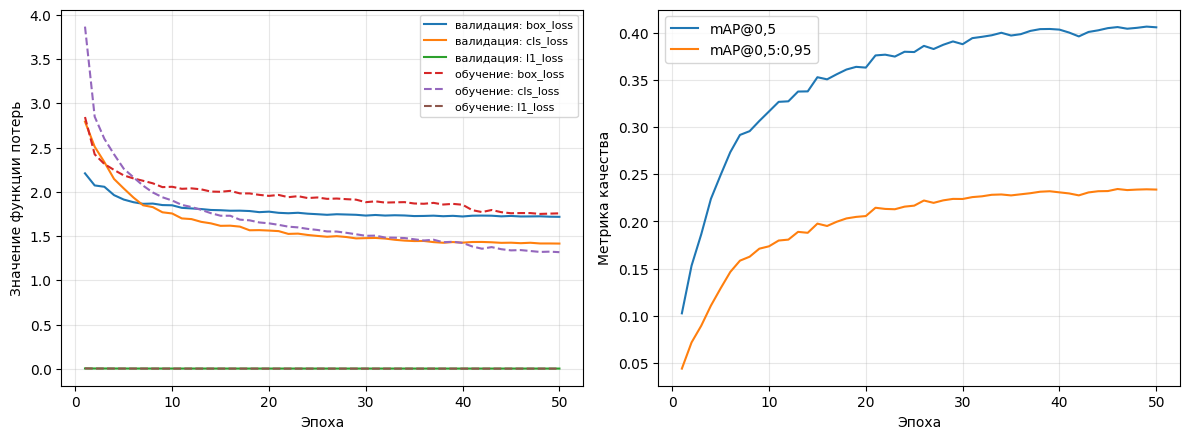

In [11]:
import matplotlib.pyplot as plt

df = pd.read_csv(RUNS / NAME / "results.csv")
df.columns = df.columns.str.strip()
print(list(df.columns))

fit = 0.1 * df["metrics/mAP50(B)"] + 0.9 * df["metrics/mAP50-95(B)"]
b = df.loc[fit.idxmax()]
print(f"Лучшая эпоха: {int(b['epoch'])}  mAP50={b['metrics/mAP50(B)']:.4f}  "
      f"mAP50-95={b['metrics/mAP50-95(B)']:.4f}  P={b['metrics/precision(B)']:.4f}  R={b['metrics/recall(B)']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c in [c for c in df.columns if c.startswith("val/") and "loss" in c]:
    ax[0].plot(df["epoch"], df[c], label=c.replace("val/", "валидация: "))
for c in [c for c in df.columns if c.startswith("train/") and "loss" in c]:
    ax[0].plot(df["epoch"], df[c], "--", label=c.replace("train/", "обучение: "))
ax[0].set_xlabel("Эпоха"); ax[0].set_ylabel("Значение функции потерь"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP@0,5")
ax[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@0,5:0,95")
ax[1].set_xlabel("Эпоха"); ax[1].set_ylabel("Метрика качества"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUNS / f"{NAME}_curves.png", dpi=200); plt.show()

## 6. Валидация лучшей модели: метрики по классам и скорость
Перед сравнением головы проверяем, какой режим вывода используется (у YOLO26 есть голова без NMS, ограниченная 300 объектами, а в VisDrone встречаются кадры с 902).

In [12]:
BEST = str(RUNS / NAME / "weights" / "best.pt")

def run_val(split="val", suffix="", **kw):
    m = YOLO(BEST)
    return m.val(data=DATA_YAML, split=split, imgsz=IMGSZ, batch=BATCH, workers=WORKERS, device=0,
                 max_det=902, save_json=True, plots=True,
                 project=str(RUNS), name=f"{NAME}_{split}{suffix}", exist_ok=True, **kw)

head = YOLO(BEST).model.model[-1]
print("Голова:", type(head).__name__, "| end2end =", getattr(head, "end2end", "нет атрибута"),
      "| reg_max =", getattr(head, "reg_max", "?"))

r = run_val("val")
rows = [{"Класс": r.names[i], "P": r.box.p[k], "R": r.box.r[k],
         "AP50": r.box.ap50[k], "AP50-95": r.box.maps[i]} for k, i in enumerate(r.box.ap_class_index)]
tab = pd.DataFrame(rows).round(3)
print(tab.to_string(index=False))
print(f"\nВсего: mAP50={r.box.map50:.4f}  mAP50-95={r.box.map:.4f}  P={r.box.mp:.4f}  R={r.box.mr:.4f}")
print("Скорость, мс/кадр:", {k: round(v, 1) for k, v in r.speed.items()})
tab.to_csv(RUNS / f"{NAME}_val_per_class.csv", index=False)

Голова: Detect | end2end = False | reg_max = 1
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s-visdrone-p2 summary (fused): 151 layers, 9,434,120 parameters, 0 gradients, 24.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2828.7±632.1 MB/s, size: 145.3 KB)
val: Scanning /tmp/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 176.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 2.1it/s 16.7s
                   all        548      38759      0.523        0.4      0.407      0.235
            pedestrian        520       8844      0.561      0.427      0.459      0.205
                people        482       5125      0.568      0.327       0.36      0.135
               bicycle        364       1287      0.308      0.177      0.147     0.0622
                   car        515      14064      0.718      0.798 

In [13]:
# Необязательно: режим без NMS (по документации по умолчанию используется путь с NMS).
# Лимит 300 объектов у режима без NMS может занизить AP на плотных кадрах VisDrone.
try:
    r2 = run_val("val", suffix="_nonms", nms=False)
    print(f"без NMS      : mAP50={r2.box.map50:.4f}  mAP50-95={r2.box.map:.4f}")
    print(f"по умолчанию : mAP50={r.box.map50:.4f}  mAP50-95={r.box.map:.4f}")
except Exception as e:
    print("Не удалось:", repr(e))

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s-visdrone-p2 summary (fused): 152 layers, 9,434,120 parameters, 0 gradients, 24.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2066.8±503.2 MB/s, size: 142.1 KB)
val: Scanning /tmp/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 164.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 2.2it/s 15.9s
                   all        548      38759      0.524       0.39      0.399      0.227
            pedestrian        520       8844        0.6      0.407       0.46      0.203
                people        482       5125       0.52      0.313       0.34      0.127
               bicycle        364       1287      0.296      0.192      0.154     0.0642
                   car        515      14064       0.73      0.788      0.808      0.548
                   van   

## 7. AP по размерам объектов (small / medium / large) через pycocotools
Ultralytics этого не считает. Строим разметку COCO из меток YOLO и оцениваем `predictions.json` из шага 6. Площади считаются в пикселях исходных изображений (small < 32², medium 32²–96², large > 96²).

In [14]:
import json, numpy as np
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def build_coco_gt(split, out):
    imgs, anns, aid = [], [], 1
    for p in sorted((ROOT / "images" / split).glob("*.jpg")):
        w, h = Image.open(p).size
        imgs.append({"id": p.stem, "file_name": p.name, "width": w, "height": h})
        lf = ROOT / "labels" / split / (p.stem + ".txt")
        if not lf.exists(): continue
        for line in lf.read_text().splitlines():
            if not line.strip(): continue
            c, xc, yc, bw, bh = line.split()[:5]
            bw, bh = float(bw) * w, float(bh) * h
            x, y = float(xc) * w - bw / 2, float(yc) * h - bh / 2
            anns.append({"id": aid, "image_id": p.stem, "category_id": int(c) + 1,
                         "bbox": [x, y, bw, bh], "area": bw * bh, "iscrowd": 0}); aid += 1
    cats = [{"id": i + 1, "name": n} for i, n in enumerate(NAMES)]
    json.dump({"images": imgs, "annotations": anns, "categories": cats}, open(out, "w"))
    return anns

def coco_size_ap(split, pred_json):
    gt_path = str(TEMP / f"gt_{split}.json")
    anns = build_coco_gt(split, gt_path)
    a = np.array([x["area"] for x in anns])
    print(f"Объектов: {len(a)}  small={np.mean(a < 32**2):.1%}  "
          f"medium={np.mean((a >= 32**2) & (a < 96**2)):.1%}  large={np.mean(a >= 96**2):.1%}")
    preds = json.load(open(pred_json))
    print("category_id в предсказаниях:", sorted({p["category_id"] for p in preds}), "| пример:", preds[0])
    for p in preds: p["image_id"] = str(p["image_id"])
    gt = COCO(gt_path); dt = gt.loadRes(preds)
    E = COCOeval(gt, dt, "bbox"); E.params.maxDets = [1, 10, 1000]   # кадры до 902 объектов
    E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    pr = E.eval["precision"][:, :, :, 0, 2]      # IoU x recall x класс, area=all, maxDets=1000
    ap_all = float(pr[pr > -1].mean())           # s[0] даёт -1 из-за нестандартного maxDets
    return {"AP": ap_all, "AP50": s[1], "AP75": s[2], "AP_small": s[3], "AP_medium": s[4], "AP_large": s[5]}

size_ap = coco_size_ap("val", r.save_dir / "predictions.json")
print({k: round(v, 4) for k, v in size_ap.items()})
json.dump(size_ap, open(RUNS / f"{NAME}_val_size_ap.json", "w"), indent=1)

Объектов: 38759  small=68.6%  medium=28.7%  large=2.8%
category_id в предсказаниях: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | пример: {'image_id': '0000360_05685_d_0000742', 'file_name': '0000360_05685_d_0000742.jpg', 'category_id': 4, 'bbox': [373.827, 318.104, 144.043, 117.883], 'score': 0.89678}
loading annotations into memory...
Done (t=0.13s)
creating index...
index created!
Loading and preparing results...
DONE (t=2.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=110.13s).
Accumulating evaluation results...
DONE (t=3.63s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=1000 ] = 0.407
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=1000 ] = 0.234
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=1000 ] = 0.145
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=1000 ] = 0.349
 Avera

In [15]:
drive_push()

## 8. Тестовая выборка (test-dev) — запускать один раз, в самом конце
Только после того, как выбраны финальная модель и настройки.

In [16]:
# rt = run_val("test")
# print(f"test-dev: mAP50={rt.box.map50:.4f}  mAP50-95={rt.box.map:.4f}")